<a href="https://colab.research.google.com/github/Srikhar27/CSET_343/blob/main/AIH_Lab_10(E23CSEU0591).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install wfdb numpy pandas matplotlib seaborn scipy scikit-learn

In [2]:
import os
import random
import warnings

import wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.signal import butter, sosfiltfilt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))
print("All libraries imported successfully!")

TensorFlow Version: 2.21.0
GPU Available: []
All libraries imported successfully!


In [3]:
# Create dataset directory
DATA_DIR = "mitdb"

os.makedirs(DATA_DIR, exist_ok=True)

# Download MIT-BIH Arrhythmia Database
wfdb.dl_database(
    "mitdb",
    dl_dir=DATA_DIR
)

print("MIT-BIH dataset downloaded successfully!")

Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

In [4]:
# Get all record names
records = wfdb.get_record_list("mitdb")

print("Total recordings:", len(records))
print("\nRecord names:")
print(records)

print("\nFirst five recordings:")
print(records[:5])

Total recordings: 48

Record names:
['100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '111', '112', '113', '114', '115', '116', '117', '118', '119', '121', '122', '123', '124', '200', '201', '202', '203', '205', '207', '208', '209', '210', '212', '213', '214', '215', '217', '219', '220', '221', '222', '223', '228', '230', '231', '232', '233', '234']

First five recordings:
['100', '101', '102', '103', '104']


In [5]:
# Load ECG recording
record = wfdb.rdrecord(os.path.join(DATA_DIR, "100"))

# Load annotations
annotation = wfdb.rdann(
    os.path.join(DATA_DIR, "100"),
    "atr"
)

# Extract ECG signal
ecg_signal = record.p_signal

print("Signal Shape:", ecg_signal.shape)
print("Sampling Frequency:", record.fs)
print("Channels:", record.sig_name)
print("Number of annotations:", len(annotation.sample))

Signal Shape: (650000, 2)
Sampling Frequency: 360
Channels: ['MLII', 'V5']
Number of annotations: 2274


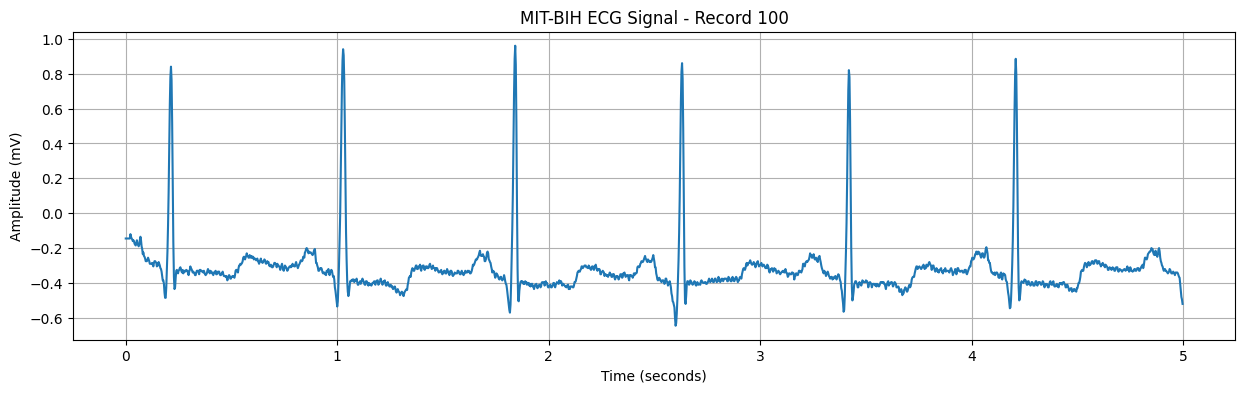

In [6]:
# Select first channel
signal = ecg_signal[:, 0]

# Plot first 5 seconds
fs = record.fs
duration = 5

time = np.arange(len(signal)) / fs

plt.figure(figsize=(15, 4))

plt.plot(
    time[:duration * fs],
    signal[:duration * fs]
)

plt.title("MIT-BIH ECG Signal - Record 100")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)

plt.show()

In [7]:
from collections import Counter

symbol_counts = Counter(annotation.symbol)

print("Heartbeat annotation symbols:\n")

for symbol, count in symbol_counts.items():
    print(symbol, ":", count)

Heartbeat annotation symbols:

+ : 1
N : 2239
A : 33
V : 1


In [8]:
# AAMI annotation mapping

AAMI_MAP = {
    # Normal
    'N': 0,
    'L': 0,
    'R': 0,
    'e': 0,
    'j': 0,

    # Supraventricular
    'A': 1,
    'a': 1,
    'J': 1,
    'S': 1,

    # Ventricular
    'V': 2,
    'E': 2,
    '!': 2,

    # Fusion
    'F': 3,

    # Unknown
    'Q': 4,
    '?': 4
}

CLASS_NAMES = ['N', 'S', 'V', 'F', 'Q']

print("AAMI classes:")
for i, name in enumerate(CLASS_NAMES):
    print(i, ":", name)

AAMI classes:
0 : N
1 : S
2 : V
3 : F
4 : Q


AAMI Class Distribution:

N : 2239
S : 33
V : 1
F : 0
Q : 0


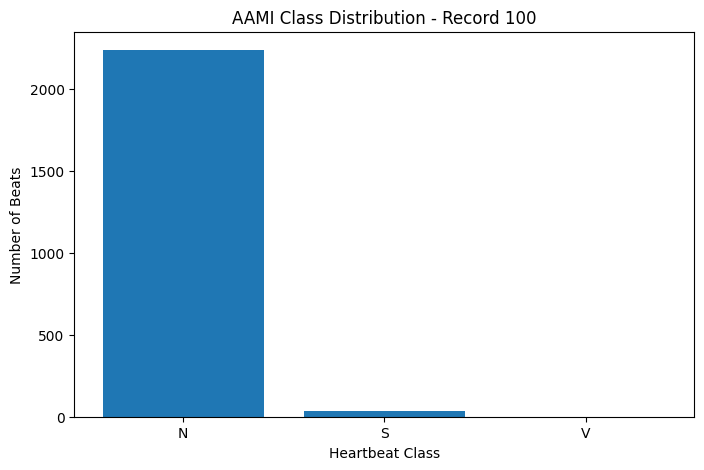

In [9]:
# Count AAMI classes in record 100
class_counts = Counter()

for symbol in annotation.symbol:

    if symbol in AAMI_MAP:

        label = AAMI_MAP[symbol]

        class_counts[CLASS_NAMES[label]] += 1

print("AAMI Class Distribution:\n")

for cls in CLASS_NAMES:
    print(cls, ":", class_counts[cls])

# Plot distribution
plt.figure(figsize=(8, 5))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title("AAMI Class Distribution - Record 100")
plt.xlabel("Heartbeat Class")
plt.ylabel("Number of Beats")

plt.show()

Task - 2


In [10]:
# Records commonly excluded because of paced rhythms
paced_records = ['102', '104', '107', '217']

# Remove paced records
clean_records = [
    r for r in records
    if r not in paced_records
]

print("Original records:", len(records))
print("Removed records:", paced_records)
print("Remaining records:", len(clean_records))

Original records: 48
Removed records: ['102', '104', '107', '217']
Remaining records: 44


In [11]:
def filter_ecg(signal, fs=360):

    # Butterworth bandpass filter
    low = 0.5
    high = 40

    sos = butter(
        3,
        [low, high],
        btype='bandpass',
        fs=fs,
        output='sos'
    )

    # Zero-phase filtering
    filtered_signal = sosfiltfilt(
        sos,
        signal
    )

    return filtered_signal

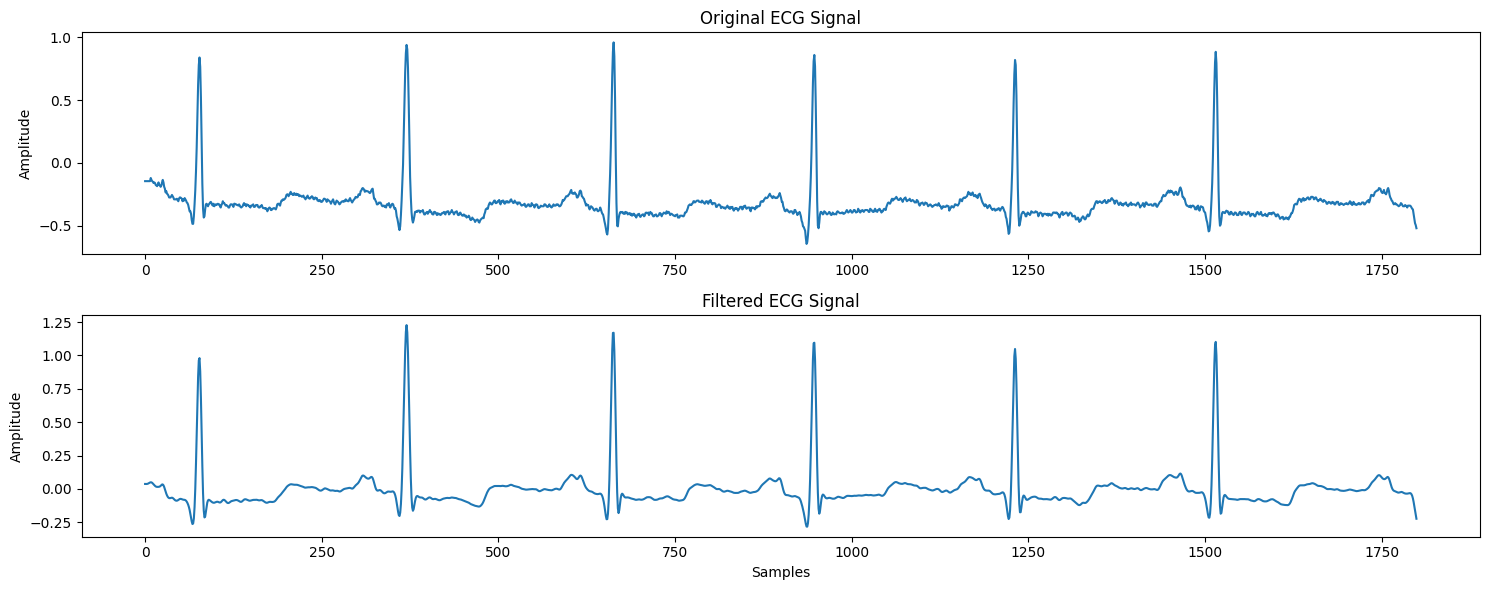

In [12]:
# Original signal
original = record.p_signal[:, 0]

# Filtered signal
filtered = filter_ecg(original, fs=360)

# Plot comparison
plt.figure(figsize=(15, 6))

plt.subplot(2, 1, 1)
plt.plot(original[:1800])
plt.title("Original ECG Signal")
plt.ylabel("Amplitude")

plt.subplot(2, 1, 2)
plt.plot(filtered[:1800])
plt.title("Filtered ECG Signal")
plt.ylabel("Amplitude")
plt.xlabel("Samples")

plt.tight_layout()
plt.show()

In [13]:
# Samples before and after R-peak
BEFORE = 90
AFTER = 162

WINDOW_SIZE = BEFORE + AFTER

def extract_heartbeats(signal, annotation):

    beats = []
    labels = []

    for sample, symbol in zip(
        annotation.sample,
        annotation.symbol
    ):

        # Ignore non-beat and unsupported annotations
        if symbol not in AAMI_MAP:
            continue

        # Extract heartbeat window
        start = sample - BEFORE
        end = sample + AFTER

        # Ignore beats near signal boundaries
        if start < 0 or end > len(signal):
            continue

        beat = signal[start:end]

        # Normalize each beat
        mean = np.mean(beat)
        std = np.std(beat)

        beat = (beat - mean) / (std + 1e-8)

        beats.append(beat)
        labels.append(AAMI_MAP[symbol])

    return beats, labels

In [14]:
X = []
y = []
record_ids = []

for rec in clean_records:

    try:

        # Load ECG
        rec_path = os.path.join(DATA_DIR, rec)

        ecg = wfdb.rdrecord(rec_path)

        ann = wfdb.rdann(rec_path, 'atr')

        fs = ecg.fs

        # Select MLII if available
        if 'MLII' in ecg.sig_name:
            channel = ecg.sig_name.index('MLII')
        else:
            channel = 0

        signal = ecg.p_signal[:, channel]

        # Apply bandpass filter
        filtered_signal = filter_ecg(
            signal,
            fs=fs
        )

        # Extract heartbeat segments
        beats, labels = extract_heartbeats(
            filtered_signal,
            ann
        )

        X.extend(beats)
        y.extend(labels)

        record_ids.extend([rec] * len(labels))

        print(
            f"Record {rec}: "
            f"{len(beats)} beats extracted"
        )

    except Exception as e:

        print(f"Error processing {rec}: {e}")

# Convert to NumPy arrays
X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.int32)
record_ids = np.asarray(record_ids)

print("\nProcessing completed!")

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Record IDs shape:", record_ids.shape)

Record 100: 2271 beats extracted
Record 101: 1864 beats extracted
Record 103: 2083 beats extracted
Record 105: 2572 beats extracted
Record 106: 2027 beats extracted
Record 108: 1762 beats extracted
Record 109: 2531 beats extracted
Record 111: 2124 beats extracted
Record 112: 2538 beats extracted
Record 113: 1794 beats extracted
Record 114: 1879 beats extracted
Record 115: 1952 beats extracted
Record 116: 2411 beats extracted
Record 117: 1534 beats extracted
Record 118: 2277 beats extracted
Record 119: 1987 beats extracted
Record 121: 1862 beats extracted
Record 122: 2475 beats extracted
Record 123: 1517 beats extracted
Record 124: 1618 beats extracted
Record 200: 2600 beats extracted
Record 201: 1963 beats extracted
Record 202: 2135 beats extracted
Record 203: 2980 beats extracted
Record 205: 2655 beats extracted
Record 207: 2331 beats extracted
Record 208: 2953 beats extracted
Record 209: 3004 beats extracted
Record 210: 2648 beats extracted
Record 212: 2747 beats extracted
Record 213

  Class  Count
0     N  90088
1     S   2781
2     V   7480
3     F    802
4     Q     15


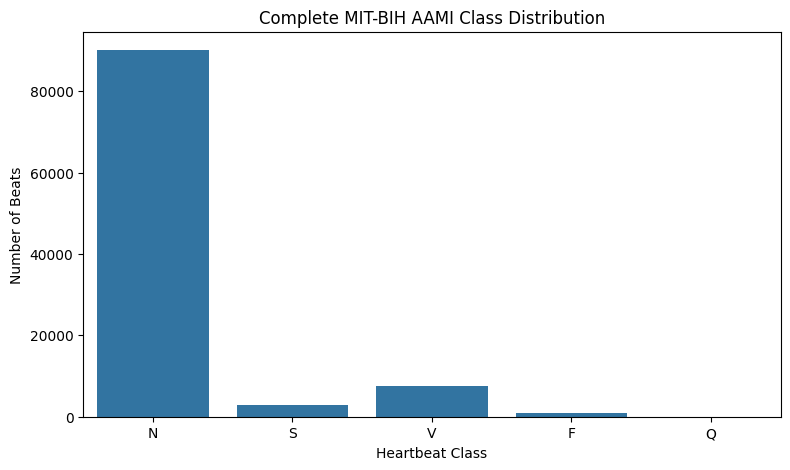

In [15]:
unique, counts = np.unique(
    y,
    return_counts=True
)

distribution = pd.DataFrame({
    'Class': [CLASS_NAMES[i] for i in unique],
    'Count': counts
})

print(distribution)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=distribution,
    x='Class',
    y='Count'
)

plt.title("Complete MIT-BIH AAMI Class Distribution")
plt.xlabel("Heartbeat Class")
plt.ylabel("Number of Beats")

plt.show()

In [16]:
# Add feature dimension
X = X.reshape(
    X.shape[0],
    X.shape[1],
    1
)

print("Final X shape:", X.shape)
print("Final y shape:", y.shape)

Final X shape: (101166, 252, 1)
Final y shape: (101166,)


In [17]:
# Create record-level dataset
record_df = pd.DataFrame({
    'record': clean_records
})

# Record 201 and 202 belong to the same subject
record_df['patient'] = record_df['record'].apply(
    lambda r: 'subject_201_202'
    if r in ['201', '202']
    else r
)

# First split: training + validation vs testing
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

train_val_idx, test_idx = next(
    split1.split(
        record_df,
        groups=record_df['patient']
    )
)

train_val_records = record_df.iloc[
    train_val_idx
]['record'].tolist()

test_records = record_df.iloc[
    test_idx
]['record'].tolist()


# Second split: training vs validation
train_val_df = record_df[
    record_df['record'].isin(train_val_records)
]

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.1875,
    random_state=SEED
)

train_idx, val_idx = next(
    split2.split(
        train_val_df,
        groups=train_val_df['patient']
    )
)

train_records = train_val_df.iloc[
    train_idx
]['record'].tolist()

val_records = train_val_df.iloc[
    val_idx
]['record'].tolist()


# Convert record splits into beat-level masks
train_mask = np.isin(record_ids, train_records)
val_mask = np.isin(record_ids, val_records)
test_mask = np.isin(record_ids, test_records)

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTraining records:", len(train_records))
print("Validation records:", len(val_records))
print("Testing records:", len(test_records))

Training: (64505, 252, 1)
Validation: (15159, 252, 1)
Testing: (21502, 252, 1)

Training records: 28
Validation records: 7
Testing records: 9


In [18]:
for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:

    print("\n", name, "Distribution")

    counts = np.bincount(
        labels,
        minlength=5
    )

    for i, cls in enumerate(CLASS_NAMES):
        print(cls, ":", counts[i])


 Training Distribution
N : 58567
S : 661
V : 4863
F : 403
Q : 11

 Validation Distribution
N : 14360
S : 138
V : 632
F : 27
Q : 2

 Testing Distribution
N : 17161
S : 1982
V : 1985
F : 372
Q : 2


In [19]:
classes_present = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes_present,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes_present, weights)
}

print("Class weights:")

for cls, weight in class_weights.items():
    print(CLASS_NAMES[cls], ":", round(weight, 4))

Class weights:
N : 0.2203
S : 19.5174
V : 2.6529
F : 32.0124
Q : 1172.8182


Task - 3

In [20]:
def build_model(model_type):

    model = keras.Sequential()

    # Input layer
    model.add(
        layers.Input(
            shape=(WINDOW_SIZE, 1)
        )
    )

    # Recurrent layer
    if model_type == "RNN":

        model.add(
            layers.SimpleRNN(
                64,
                activation='tanh'
            )
        )

    elif model_type == "LSTM":

        model.add(
            layers.LSTM(
                64
            )
        )

    elif model_type == "GRU":

        model.add(
            layers.GRU(
                64
            )
        )

    # Dropout
    model.add(
        layers.Dropout(0.3)
    )

    # Dense layer
    model.add(
        layers.Dense(
            32,
            activation='relu'
        )
    )

    # Output layer
    model.add(
        layers.Dense(
            5,
            activation='softmax'
        )
    )

    # Compile model
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),

        loss='sparse_categorical_crossentropy',

        metrics=['accuracy']
    )

    return model

In [21]:
for model_type in ["RNN", "LSTM", "GRU"]:

    print("\n", "=" * 50)
    print(model_type, "MODEL")
    print("=" * 50)

    model = build_model(model_type)

    model.summary()


RNN MODEL


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,469 (25.27 KB)

 Trainable params: 6,469 (25.27 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,109 (59.02 KB)

 Trainable params: 15,109 (59.02 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
# Build RNN
rnn_model = build_model("RNN")

# Early stopping
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Train RNN
rnn_history = rnn_model.fit(
    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=30,
    batch_size=128,

    class_weight=class_weights,

    callbacks=[early_stop],

    verbose=1
)

print("RNN Training Completed!")

Epoch 1/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 35s 65ms/step - accuracy: 0.3045 - loss: 1.5889 - val_accuracy: 0.1792 - val_loss: 1.4609
Epoch 2/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 31s 61ms/step - accuracy: 0.1926 - loss: 1.7013 - val_accuracy: 0.9323 - val_loss: 1.3258
Epoch 3/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 31s 61ms/step - accuracy: 0.2748 - loss: 1.5955 - val_accuracy: 0.0057 - val_loss: 1.3126
Epoch 4/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 33s 66ms/step - accuracy: 0.2435 - loss: 1.5420 - val_accuracy: 0.1716 - val_loss: 1.6505
Epoch 5/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 30s 60ms/step - accuracy: 0.2239 - loss: 1.6338 - val_accuracy: 0.1168 - val_loss: 1.3558
Epoch 6/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 31s 61ms/step - accuracy: 0.3438 - loss: 1.5974 - val_accuracy: 0.0268 - val_loss: 1.3966
Epoch 7/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 30s 60ms/step - accuracy: 0.3086 - loss: 1.5062 - val_accuracy: 0.8537 - val_loss: 1.2321
Epoch 8/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 31s 62ms/step - accuracy: 0.2173 - loss: 1.5997 - 

In [23]:
# Build LSTM
lstm_model = build_model("LSTM")

# Early stopping
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Train LSTM
lstm_history = lstm_model.fit(
    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=30,
    batch_size=128,

    class_weight=class_weights,

    callbacks=[early_stop],

    verbose=1
)

print("LSTM Training Completed!")

Epoch 1/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 159s 313ms/step - accuracy: 0.2229 - loss: 1.6422 - val_accuracy: 0.0544 - val_loss: 1.5605
Epoch 2/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 202s 312ms/step - accuracy: 0.1712 - loss: 1.4746 - val_accuracy: 0.6328 - val_loss: 1.4275
Epoch 3/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 162s 321ms/step - accuracy: 0.2932 - loss: 1.3641 - val_accuracy: 0.5230 - val_loss: 1.4474
Epoch 4/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 160s 318ms/step - accuracy: 0.2800 - loss: 1.3867 - val_accuracy: 0.2180 - val_loss: 1.5137
Epoch 5/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 156s 310ms/step - accuracy: 0.2599 - loss: 1.2850 - val_accuracy: 0.5833 - val_loss: 1.3925
Epoch 6/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 207s 320ms/step - accuracy: 0.2734 - loss: 1.2027 - val_accuracy: 0.1826 - val_loss: 1.5157
Epoch 7/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 156s 310ms/step - accuracy: 0.2562 - loss: 1.1311 - val_accuracy: 0.3193 - val_loss: 1.4678
Epoch 8/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 155s 308ms/step - accuracy: 0.2093 -

In [24]:
# Build GRU
gru_model = build_model("GRU")

# Early stopping
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Train GRU
gru_history = gru_model.fit(
    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=30,
    batch_size=128,

    class_weight=class_weights,

    callbacks=[early_stop],

    verbose=1
)

print("GRU Training Completed!")

Epoch 1/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 199s 390ms/step - accuracy: 0.4028 - loss: 1.6956 - val_accuracy: 0.1616 - val_loss: 1.6039
Epoch 2/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 195s 388ms/step - accuracy: 0.3250 - loss: 1.5648 - val_accuracy: 0.2607 - val_loss: 1.5956
Epoch 3/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 202s 401ms/step - accuracy: 0.3761 - loss: 1.5363 - val_accuracy: 0.1222 - val_loss: 1.5586
Epoch 4/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 193s 383ms/step - accuracy: 0.1555 - loss: 1.5265 - val_accuracy: 0.1110 - val_loss: 1.6588
Epoch 5/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 193s 383ms/step - accuracy: 0.2763 - loss: 1.4266 - val_accuracy: 0.2759 - val_loss: 1.5337
Epoch 6/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 194s 385ms/step - accuracy: 0.2479 - loss: 1.3079 - val_accuracy: 0.2275 - val_loss: 1.5238
Epoch 7/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 201s 400ms/step - accuracy: 0.1879 - loss: 1.2963 - val_accuracy: 0.0304 - val_loss: 1.6393
Epoch 8/30
504/504 ━━━━━━━━━━━━━━━━━━━━ 195s 385ms/step - accuracy: 0.1356 -

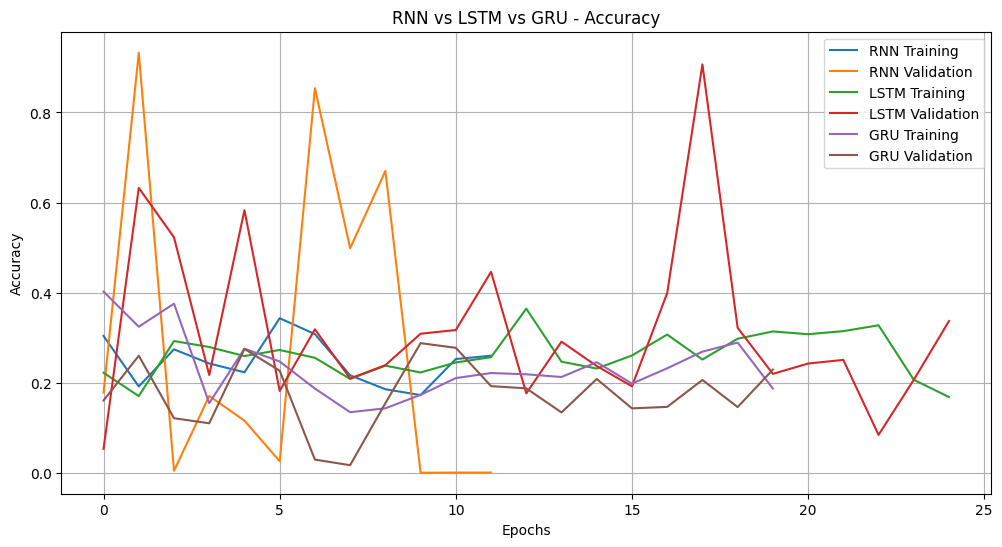

In [25]:
plt.figure(figsize=(12, 6))

plt.plot(
    rnn_history.history['accuracy'],
    label='RNN Training'
)

plt.plot(
    rnn_history.history['val_accuracy'],
    label='RNN Validation'
)

plt.plot(
    lstm_history.history['accuracy'],
    label='LSTM Training'
)

plt.plot(
    lstm_history.history['val_accuracy'],
    label='LSTM Validation'
)

plt.plot(
    gru_history.history['accuracy'],
    label='GRU Training'
)

plt.plot(
    gru_history.history['val_accuracy'],
    label='GRU Validation'
)

plt.title("RNN vs LSTM vs GRU - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()

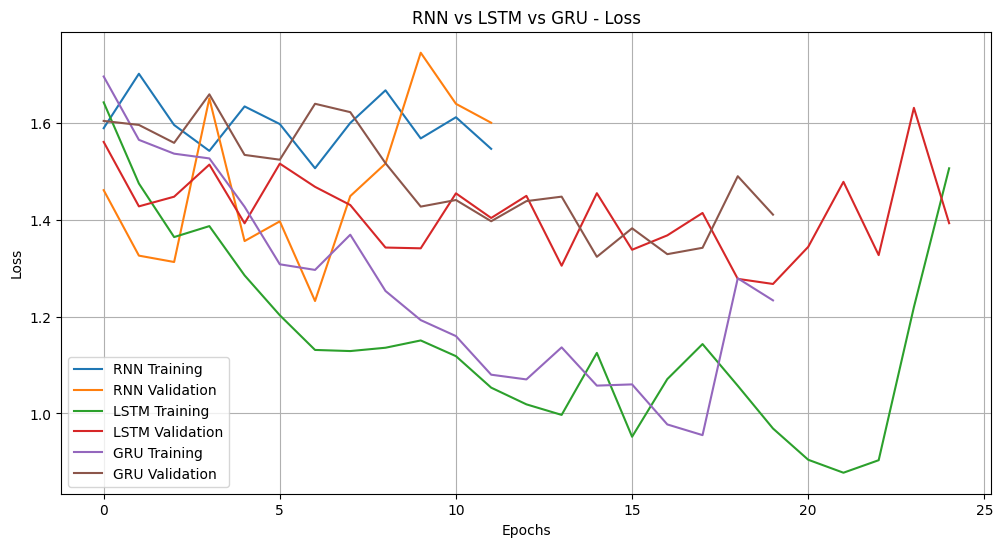

In [26]:
plt.figure(figsize=(12, 6))

plt.plot(
    rnn_history.history['loss'],
    label='RNN Training'
)

plt.plot(
    rnn_history.history['val_loss'],
    label='RNN Validation'
)

plt.plot(
    lstm_history.history['loss'],
    label='LSTM Training'
)

plt.plot(
    lstm_history.history['val_loss'],
    label='LSTM Validation'
)

plt.plot(
    gru_history.history['loss'],
    label='GRU Training'
)

plt.plot(
    gru_history.history['val_loss'],
    label='GRU Validation'
)

plt.title("RNN vs LSTM vs GRU - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

In [27]:
# Generate predictions
rnn_predictions = np.argmax(
    rnn_model.predict(X_test),
    axis=1
)

lstm_predictions = np.argmax(
    lstm_model.predict(X_test),
    axis=1
)

gru_predictions = np.argmax(
    gru_model.predict(X_test),
    axis=1
)

print("Predictions generated successfully!")

672/672 ━━━━━━━━━━━━━━━━━━━━ 16s 24ms/step
672/672 ━━━━━━━━━━━━━━━━━━━━ 22s 33ms/step
672/672 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step
Predictions generated successfully!


In [28]:
def evaluate_model(y_true, y_pred, model_name):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average='macro',
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average='macro',
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average='macro',
        zero_division=0
    )

    return {
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    }


# Evaluate all models
results = []

results.append(
    evaluate_model(
        y_test,
        rnn_predictions,
        "RNN"
    )
)

results.append(
    evaluate_model(
        y_test,
        lstm_predictions,
        "LSTM"
    )
)

results.append(
    evaluate_model(
        y_test,
        gru_predictions,
        "GRU"
    )
)

# Create comparison table
results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

Model  Accuracy  Precision   Recall  F1-Score
  RNN  0.589806   0.167443 0.228562  0.166321
 LSTM  0.428332   0.253411 0.291675  0.225286
  GRU  0.345456   0.237087 0.256289  0.188636


In [29]:
print("RNN Classification Report\n")

print(
    classification_report(
        y_test,
        rnn_predictions,
        labels=[0, 1, 2, 3, 4],
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

print("\nLSTM Classification Report\n")

print(
    classification_report(
        y_test,
        lstm_predictions,
        labels=[0, 1, 2, 3, 4],
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

print("\nGRU Classification Report\n")

print(
    classification_report(
        y_test,
        gru_predictions,
        labels=[0, 1, 2, 3, 4],
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

RNN Classification Report

              precision    recall  f1-score   support

           N       0.78      0.73      0.76     17161
           S       0.02      0.01      0.01      1982
           V       0.00      0.00      0.00      1985
           F       0.04      0.41      0.07       372
           Q       0.00      0.00      0.00         2

    accuracy                           0.59     21502
   macro avg       0.17      0.23      0.17     21502
weighted avg       0.63      0.59      0.61     21502


LSTM Classification Report

              precision    recall  f1-score   support

           N       0.87      0.44      0.58     17161
           S       0.08      0.07      0.07      1982
           V       0.28      0.75      0.40      1985
           F       0.04      0.20      0.07       372
           Q       0.00      0.00      0.00         2

    accuracy                           0.43     21502
   macro avg       0.25      0.29      0.23     21502
weighted avg       0.

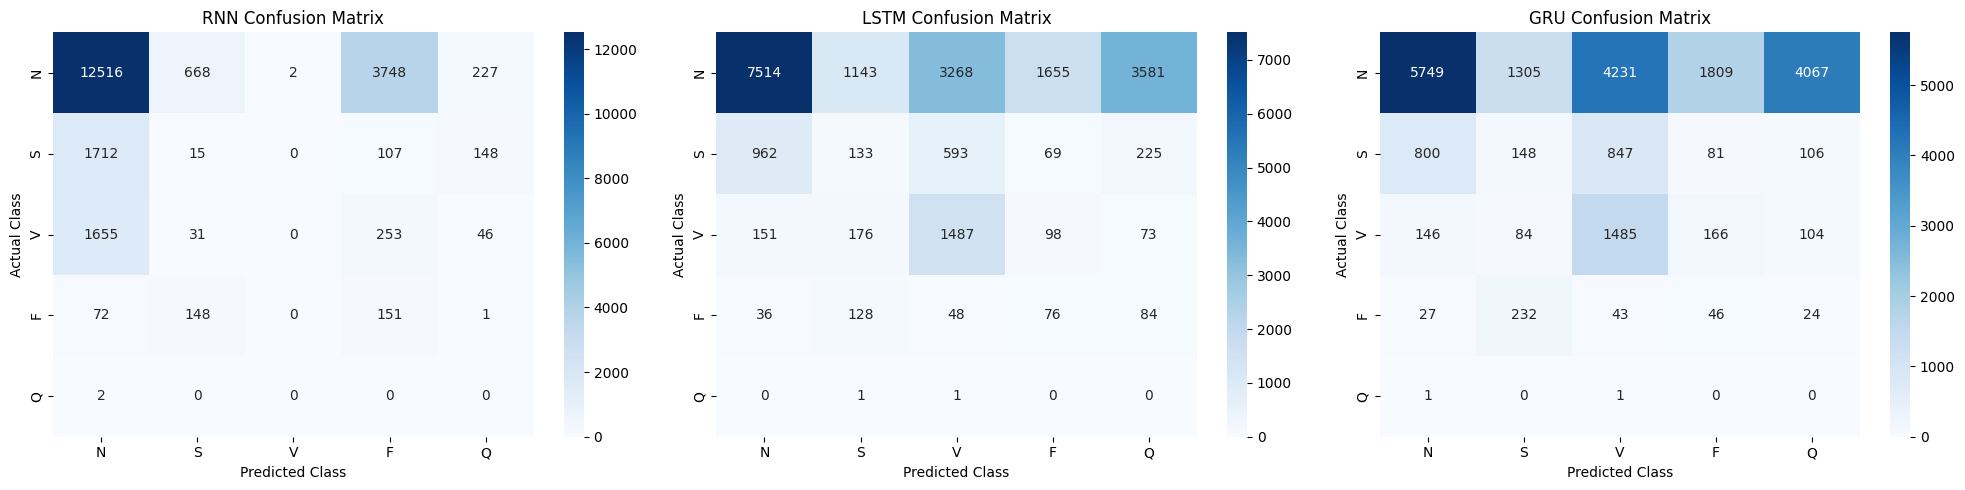

In [30]:
predictions = {
    "RNN": rnn_predictions,
    "LSTM": lstm_predictions,
    "GRU": gru_predictions
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 5)
)

for ax, (name, pred) in zip(
    axes,
    predictions.items()
):

    cm = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1, 2, 3, 4]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        ax=ax
    )

    ax.set_title(name + " Confusion Matrix")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

Comparing 3 models

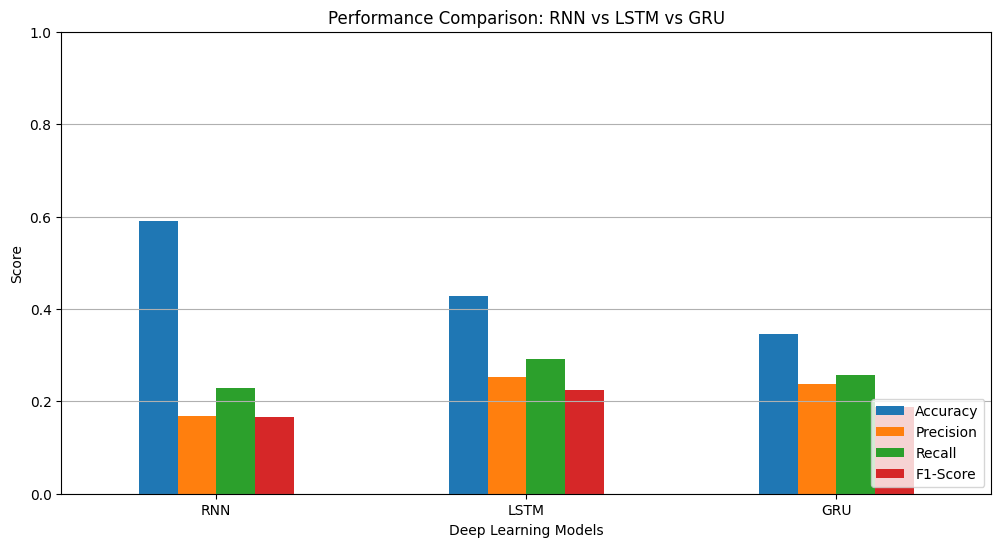

In [31]:
metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score'
]

results_df.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Performance Comparison: RNN vs LSTM vs GRU")
plt.xlabel("Deep Learning Models")
plt.ylabel("Score")

plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y')

plt.show()

In [32]:
best_model = results_df.loc[
    results_df['F1-Score'].idxmax()
]

print("Best Performing Model")
print("---------------------")

print("Model:", best_model['Model'])

print(
    "Accuracy:",
    round(best_model['Accuracy'] * 100, 2), "%"
)

print(
    "Precision:",
    round(best_model['Precision'] * 100, 2), "%"
)

print(
    "Recall:",
    round(best_model['Recall'] * 100, 2), "%"
)

print(
    "F1-Score:",
    round(best_model['F1-Score'] * 100, 2), "%"
)

Best Performing Model
---------------------
Model: LSTM
Accuracy: 42.83 %
Precision: 25.34 %
Recall: 29.17 %
F1-Score: 22.53 %


In [33]:
# Save all trained models

rnn_model.save("RNN_ECG_Model.keras")

lstm_model.save("LSTM_ECG_Model.keras")

gru_model.save("GRU_ECG_Model.keras")

# Save performance comparison
results_df.to_csv(
    "ECG_Model_Comparison.csv",
    index=False
)

print("All models and results saved successfully!")

All models and results saved successfully!
